In [1]:
# Some sample code for importing model which has been downloaded from the HEC

from problems.pdtrp.problem_pdtrp import PDTRPDataset
from problems.pdcvrp.problem_pdcvrp import PDCVRPDataset
from problems.pdtrp_tw.problem_pdtrptw import PDTRPTWDataset
from problems.pdcvrp_tw.problem_pdcvrptw import PDCVRPTWDataset

from torch.utils.data import DataLoader

from utils import load_model, move_to
from train import set_decode_type
import torch
from tqdm import tqdm

use_cuda = torch.cuda.is_available()
device = torch.device("cuda:0" if use_cuda else "cpu")
problem_type = 'PDCVRP'

if problem_type == 'PDTRP':
    model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp_20250206T205558'
elif problem_type == 'PDCVRP':
    model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdcvrp_20250207T134834'

model, model_args = load_model(model_filepath)

model.to(device)
set_decode_type(model, "greedy")
model.eval()

/home/trainer1/learning-pdtsp/utils/functions.py:27: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(load_path, map_location=lambda storage, loc: storage)  #


Loading model from models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp_20250206T205558/epoch-99.pt


/home/trainer1/learning-pdtsp/utils/functions.py:43: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_data = torch.load(


DynamicAttentionModel(
  (init_embed_depot): Linear(in_features=2, out_features=128, bias=True)
  (node_embed): Linear(in_features=2, out_features=128, bias=True)
  (edge_embed): Embedding(2, 128)
  (embedder): GNNEncoder(
    (layers): ModuleList(
      (0-2): 3 x GNNLayer(
        (U): Linear(in_features=128, out_features=128, bias=True)
        (V): Linear(in_features=128, out_features=128, bias=True)
        (A): Linear(in_features=128, out_features=128, bias=True)
        (B): Linear(in_features=128, out_features=128, bias=True)
        (C): Linear(in_features=128, out_features=128, bias=True)
        (norm_h): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
        (norm_e): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      )
    )
  )
  (project_node_embeddings): Linear(in_features=128, out_features=384, bias=False)
  (project_fixed_context): Linear(in_features=128, out_features=128, bias=False)
  (project_s

In [2]:
# Function for plotting solutions
%matplotlib inline
from matplotlib import pyplot as plt

from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import numpy as np

# Code inspired by Google OR Tools plot:
# https://github.com/google/or-tools/blob/fb12c5ded7423d524fc6c95656a9bdc290a81d4d/examples/python/cvrptw_plot.py

def plot_tsp(xy, tour, ax1):
    """
    Plot the TSP tour on matplotlib axis ax1.
    """
    
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    xs, ys = xy[tour].transpose()
    xs, ys = xy[tour].transpose()
    dx = np.roll(xs, -1) - xs
    dy = np.roll(ys, -1) - ys
    d = np.sqrt(dx * dx + dy * dy)
    lengths = d.cumsum()
    
    # Scatter nodes
    ax1.scatter(xs, ys, s=40, color='blue')
    # Starting node
    ax1.scatter([xs[0]], [ys[0]], s=100, color='red')

    #label nodes
    for i, (x, y) in enumerate(xy):
        ax1.text(x, y, str(i), fontsize=12, color='green')
    
    # Arcs
    qv = ax1.quiver(
        xs, ys, dx, dy,
        scale_units='xy',
        angles='xy',
        scale=1,
    )
    
    ax1.set_title('{} nodes, total length {:.2f}'.format(len(tour), lengths[-1]))



In [12]:
%matplotlib inline
from matplotlib import pyplot as plt

from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# Code inspired by Google OR Tools plot:
# https://github.com/google/or-tools/blob/fb12c5ded7423d524fc6c95656a9bdc290a81d4d/examples/python/cvrptw_plot.py

def discrete_cmap(N, base_cmap=None):
  """
    Create an N-bin discrete colormap from the specified input map
    """
  # Note that if base_cmap is a string or None, you can simply do
  #    return plt.cm.get_cmap(base_cmap, N)
  # The following works for string, None, or a colormap instance:

  base = plt.cm.get_cmap(base_cmap)
  color_list = base(np.linspace(0, 1, N))
  cmap_name = base.name + str(N)
  return base.from_list(cmap_name, color_list, N)

def plot_vehicle_routes(all_nodes, demands, capacity, route, ax1, markersize=5, visualize_demands=False, round_demand=False):
    """
    Plot the vehicle routes on matplotlib axis ax1.
    """
    
    # route is one sequence, separating different routes with 0 (depot)
    routes = [r[r!=0] for r in np.split(route.cpu().numpy(), np.where(route==0)[0]) if (r != 0).any()]
    locs = all_nodes[1:, :].cpu().numpy()
    depot = all_nodes[0, :].cpu().numpy()
    
    demands = demands[1:].cpu().numpy()
    capacity = capacity
    
    x_dep, y_dep = depot
    ax1.plot(x_dep, y_dep, 'sk', markersize=markersize*4)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    legend = ax1.legend(loc='upper center')
    
    cmap = discrete_cmap(len(routes) + 2, 'nipy_spectral')
    dem_rects = []
    used_rects = []
    cap_rects = []
    qvs = []
    total_dist = 0
    for veh_number, r in enumerate(routes):
        color = cmap(len(routes) - veh_number) # Invert to have in rainbow order
        
        route_demands = demands[r-1]
        coords = locs[r-1, :]
        xs, ys = coords.transpose()

        total_route_demand = sum(route_demands)
        assert total_route_demand <= capacity + 1e-5
        if not visualize_demands:
            ax1.plot(xs, ys, 'o', mfc=color, markersize=markersize, markeredgewidth=0.0)
        
        dist = 0
        x_prev, y_prev = x_dep, y_dep
        cum_demand = 0
        for (x, y), d in zip(coords, route_demands):
            dist += np.sqrt((x - x_prev) ** 2 + (y - y_prev) ** 2)
            
            cap_rects.append(Rectangle((x, y), 0.01, 0.1))
            used_rects.append(Rectangle((x, y), 0.01, 0.1 * total_route_demand / capacity))
            dem_rects.append(Rectangle((x, y + 0.1 * cum_demand / capacity), 0.01, 0.1 * d / capacity))
            
            x_prev, y_prev = x, y
            cum_demand += d
            
        dist += np.sqrt((x_dep - x_prev) ** 2 + (y_dep - y_prev) ** 2)
        total_dist += dist
        qv = ax1.quiver(
            xs[:-1],
            ys[:-1],
            xs[1:] - xs[:-1],
            ys[1:] - ys[:-1],
            scale_units='xy',
            angles='xy',
            scale=1,
            color=color,
            label='R{}, # {}, c {} / {}, d {:.2f}'.format(
                veh_number, 
                len(r), 
                int(total_route_demand) if round_demand else total_route_demand, 
                int(capacity) if round_demand else capacity,
                dist
            )
        )
        
        qvs.append(qv)
        
    ax1.set_title('{} routes, total distance {:.2f}'.format(len(routes), total_dist))
    ax1.legend(handles=qvs)
    
    pc_cap = PatchCollection(cap_rects, facecolor='whitesmoke', alpha=1.0, edgecolor='lightgray')
    pc_used = PatchCollection(used_rects, facecolor='lightgray', alpha=1.0, edgecolor='lightgray')
    pc_dem = PatchCollection(dem_rects, facecolor='black', alpha=1.0, edgecolor='black')
    
    if visualize_demands:
        ax1.add_collection(pc_cap)
        ax1.add_collection(pc_used)
        ax1.add_collection(pc_dem)

In [10]:
problem_type = 'PDCVRP'
NUM_SAMPLES = 128
BATCH_SIZE = 16

filename = 'data/pdcvrp/test_data_PDCVRP.txt'

# SET SEEDS FOR REPRODUCIBILITY
np.random.seed(2512)
torch.manual_seed(2512)

if problem_type == 'PDTRP':
    dataset = PDTRPDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDCVRP':
    dataset = PDCVRPDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDTRPTW':
    dataset = PDTRPTWDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDCVRPTW':
    dataset = PDCVRPTWDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

Loading from data/pdcvrp/test_data_PDCVRP.txt...


100%|##########| 128/128 [00:00<00:00, 6467.31it/s]


In [11]:
with torch.no_grad():

    for bat in tqdm(dataloader):
        
        if problem_type == 'PDTRP':
            input = {
                'loc': move_to(bat['all_nodes'], device),
                'service_times': move_to(bat['service_times'], device),
                'arrival_times': move_to(bat['arrival_times'], device),
                'graph': move_to(bat['graph'], device)
            }
        elif problem_type == 'PDCVRP':
            input = {
                'loc': move_to(bat['all_nodes'], device),
                'service_times': move_to(bat['service_times'], device),
                'arrival_times': move_to(bat['arrival_times'], device),
                'demand': move_to(bat['demand'], device),
                'graph': move_to(bat['graph'], device)

            }

        cost, _, pi = model(input, return_pi=True)

        pi_with_depot = torch.cat((torch.zeros(pi.size(0), 1, dtype=torch.long), pi), dim=1)

        or_tools_tour = bat['tour_nodes'][0].cpu().numpy()
        

100%|██████████| 8/8 [00:05<00:00,  1.38it/s]


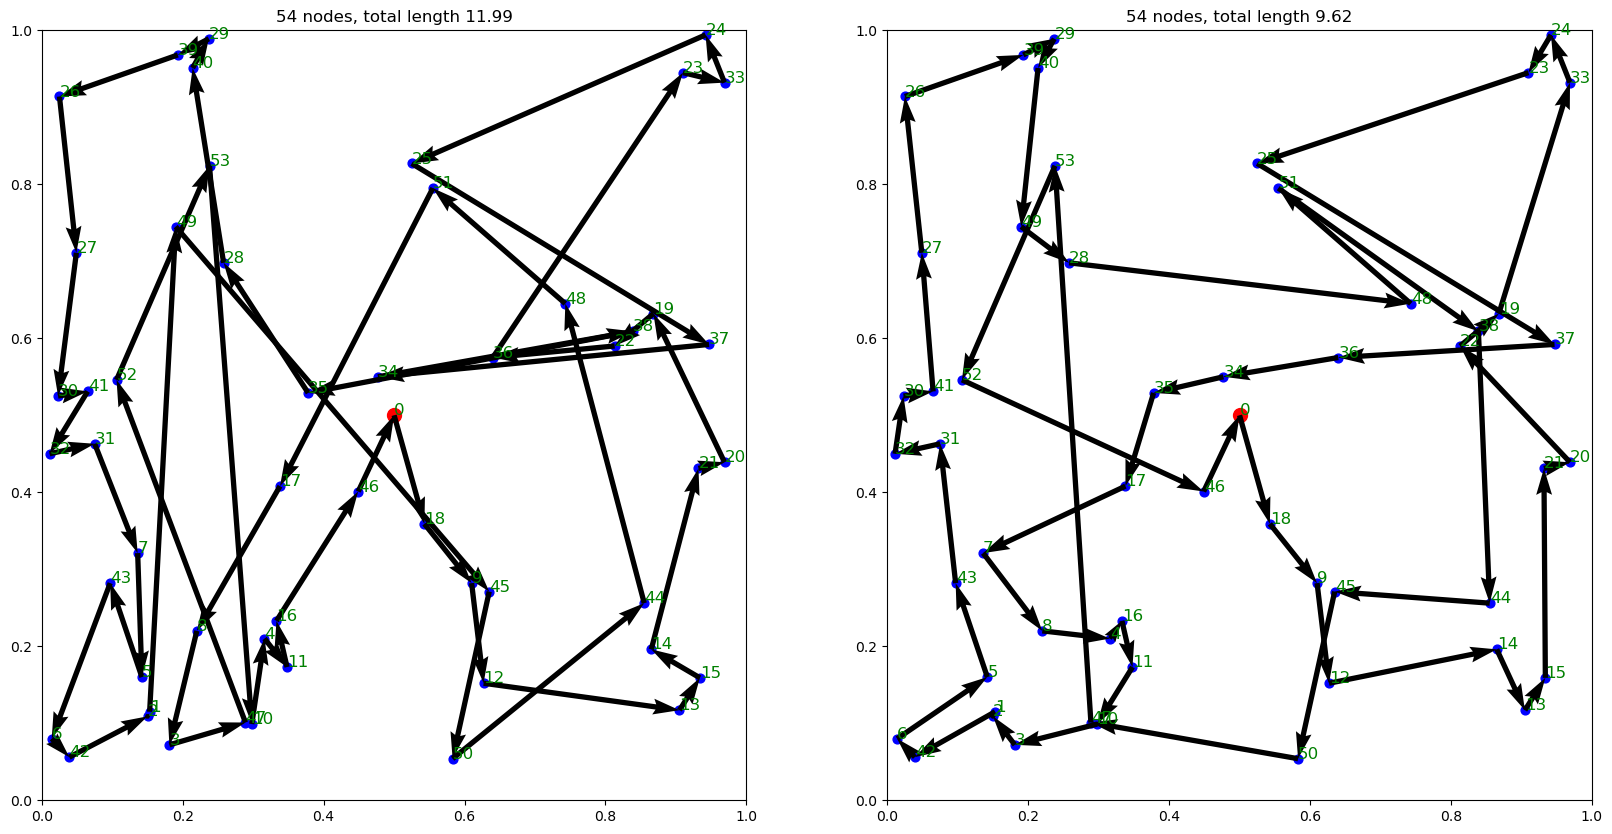

In [8]:
#plot model solution and or tools solution side by side
fig, axs = plt.subplots(1, 2, figsize=(20, 10))

plot_tsp(bat['all_nodes'][0].cpu().numpy(), pi_with_depot[0].cpu().numpy(), axs[0])
plot_tsp(bat['all_nodes'][0].cpu().numpy(), or_tools_tour, axs[1])

In [21]:
pi_with_depot

tensor([[ 0, 16,  4,  7,  9, 17, 21, 14, 19, 13, 20, 30, 18, 31, 25, 28, 29, 35,
         34, 27, 33, 37, 24, 22, 26, 41, 38, 36, 23,  1, 39,  6, 11, 46, 40,  3,
         48, 50, 49, 45, 44, 42, 43, 52,  2, 51,  5, 15, 12, 32,  8, 10, 47, 53],
        [ 0, 18, 17, 23, 20, 19, 24, 10, 14, 16, 15, 13, 12, 11, 26, 27,  7, 29,
         34,  6,  1, 35, 21,  5, 30, 38, 36, 33,  4, 40, 42, 43, 41, 22, 37, 44,
         45,  2, 25,  9, 31,  8, 39, 49, 48, 47, 51, 52, 50, 32,  3, 28, 46, 53],
        [ 0,  6,  8,  5,  7,  9, 13, 12, 10, 11, 17, 19, 21, 18, 16,  1, 24, 23,
         26, 29, 31, 34, 32, 33, 27,  3, 38, 15, 40, 36, 41, 14, 25, 22,  2, 28,
         30, 44,  4, 35, 39, 43, 42, 46, 45, 48, 49, 47, 20, 37, 50, 51, 52, 53],
        [ 0,  2,  1, 24, 21,  5,  4, 26, 29, 28, 30, 16,  3, 34, 20, 18, 27,  8,
         31, 38, 35,  6,  7, 17, 19, 42, 43, 36, 10, 15, 13, 12, 25, 37, 47, 46,
         40, 44, 11,  9, 22, 14, 48, 39, 50, 33, 45, 32, 49, 41, 51, 52, 53, 23],
        [ 0, 13,  5,  6,

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/tmp/ipykernel_446571/2709835948.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base = plt.cm.get_cmap(base_cmap)


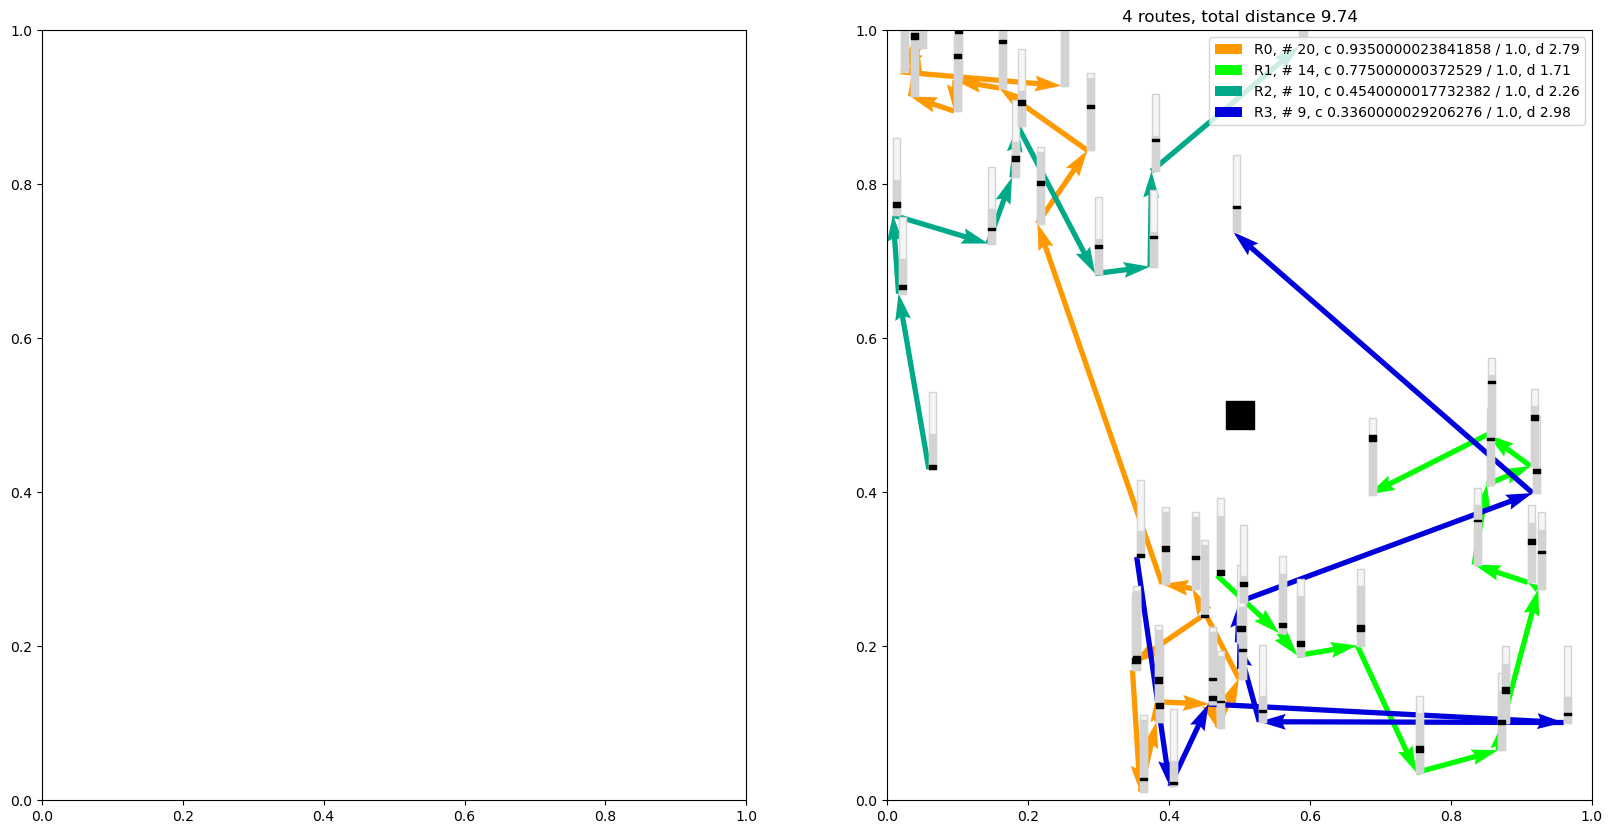

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(20, 10))
#plot_vehicle_routes(bat['all_nodes'][0], bat['demand'][0], 1.0, pi_with_depot[0], axs[0], visualize_demands=True)
plot_vehicle_routes(bat['all_nodes'][0], bat['demand'][0], 1.0, torch.tensor(or_tools_tour), axs[1], visualize_demands=True)